<a href="https://colab.research.google.com/github/EsatovinVictoria/ML_Semester5_EsatovinEbenhaezerVictoria/blob/main/Pertemuan_6/Praktikum_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 5

In [1]:
%pip install --no-cache-dir numpy matplotlib faiss-cpu annoy hnswlib

Note: you may need to restart the kernel to use updated packages.


Database shape: (45000, 20), Query shape: (500, 20)


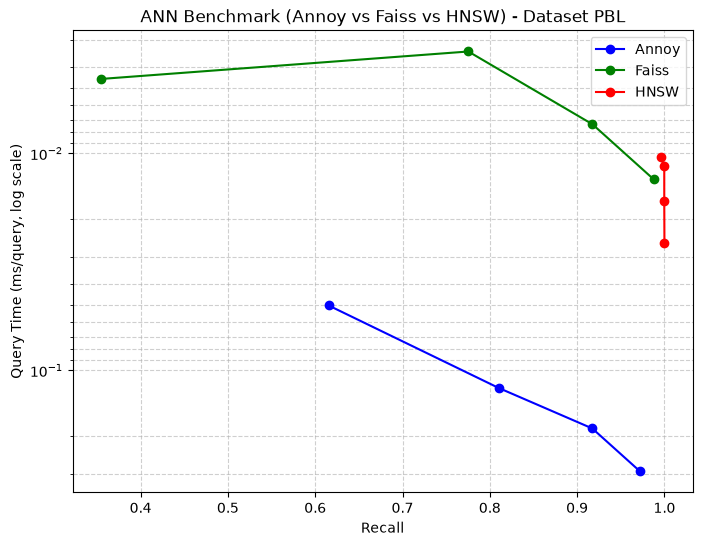

In [2]:
import pandas as pd
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# -------------------------------
# Dataset PBL (burnout_dataset1.csv)
# -------------------------------
df = pd.read_csv('burnout_dataset1.csv')
num_cols = [
    'Age', 'Monthly_Income_USD', 'Work_Hours_Per_Week', 'Job_Satisfaction',
    'Work_Life_Balance', 'Sleep_Hours', 'Anxiety_Score', 'Depression_Score',
    'Mood_Score', 'Emotional_Stability', 'Physical_Activity_Hours',
    'Meditation_Minutes', 'Screen_Time_Hours', 'Social_Media_Hours',
    'Gaming_Hours', 'Coffee_Cups_Per_Day', 'Life_Satisfaction',
    'Productivity_Score', 'Absenteeism_Days', 'Burnout_Score'
]
df_num = df[num_cols].fillna(df[num_cols].mean(numeric_only=True))

scaler = StandardScaler()
X_all = scaler.fit_transform(df_num).astype(np.float32)

# Bagi dataset: database xb (45.000 data) dan query set xq (500 data)
np.random.seed(42)
indices = np.random.permutation(len(X_all))
xb = X_all[indices[:45000]]
xq = X_all[indices[45000:45500]]
d = xb.shape[1]

print(f"Database shape: {xb.shape}, Query shape: {xq.shape}")

# -------------------------------
# Ground truth dengan FAISS brute force
# -------------------------------
index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
k = 10
_, gt_idx = index_flat.search(xq, k)

# -------------------------------
# Fungsi recall
# -------------------------------
def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

# -------------------------------
# Benchmark Annoy
# -------------------------------
def run_annoy(xb, xq, n_trees=10, search_k=1000, k=10):
    f = xb.shape[1]
    index = AnnoyIndex(f, 'euclidean')
    for i, v in enumerate(xb):
        index.add_item(i, v)
    index.build(n_trees)

    start = time.time()
    I = [index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Benchmark FAISS IVF
# -------------------------------
def run_faiss(xb, xq, nlist=100, nprobe=10, k=10):
    quantizer = faiss.IndexFlatL2(d)
    index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)
    index.train(xb)
    index.add(xb)

    index.nprobe = nprobe
    start = time.time()
    _, I = index.search(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Benchmark HNSW
# -------------------------------
def run_hnsw(xb, xq, ef=100, M=16, k=10):
    num_elements = xb.shape[0]
    p = hnswlib.Index(space='l2', dim=d)
    p.init_index(max_elements=num_elements, ef_construction=200, M=M)
    p.add_items(xb)
    p.set_ef(ef)

    start = time.time()
    I, _ = p.knn_query(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Jalankan benchmark dengan beberapa parameter
# -------------------------------
results = {"Annoy": [], "Faiss": [], "HNSW": []}

# Annoy
for sk in [200, 500, 1000, 2000]:
    rec, t = run_annoy(xb, xq, n_trees=10, search_k=sk)
    results["Annoy"].append((rec, t))

# FAISS
for npb in [1, 5, 10, 20]:
    rec, t = run_faiss(xb, xq, nlist=100, nprobe=npb)
    results["Faiss"].append((rec, t))

# HNSW
for ef in [50, 100, 200, 400]:
    rec, t = run_hnsw(xb, xq, ef=ef)
    results["HNSW"].append((rec, t))

# -------------------------------
# Visualisasi trade-off
# -------------------------------
plt.figure(figsize=(8,6))
for label, color in zip(results.keys(), ["blue","green","red"]):
    recall, qtime = zip(*results[label])
    plt.plot(recall, qtime, marker="o", label=label, color=color)

plt.xlabel("Recall")
plt.ylabel("Query Time (ms/query, log scale)")
plt.yscale("log")
plt.gca().invert_yaxis()
plt.title("ANN Benchmark (Annoy vs Faiss vs HNSW) - Dataset PBL")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()